PROJECT 4: MODELING AND EVALUATION

Dataset shape: (10000, 13)
Stayed (0): 7963
Churned (1): 2037

Training rows: 8000
Testing rows: 2000

Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'HasBalance']
Categorical features: ['Geography', 'Gender', 'AgeGroup']

Starting 5-fold cross-validation...
Completed: Logistic Regression
Completed: K-Nearest Neighbors
Completed: Decision Tree
Completed: Random Forest

CROSS-VALIDATION MODEL COMPARISON
              Model  CV Accuracy  CV Precision  CV Recall  CV F1  CV F1 Std  CV ROC-AUC
      Random Forest       0.8521        0.7363     0.4270 0.5404     0.0223      0.8440
Logistic Regression       0.7289        0.4032     0.6890 0.5085     0.0206      0.7804
K-Nearest Neighbors       0.8342        0.6491     0.4055 0.4989     0.0372      0.7749
      Decision Tree       0.7924        0.4904     0.4834 0.4867     0.0172      0.6774

Selected model: Random Forest
Sel

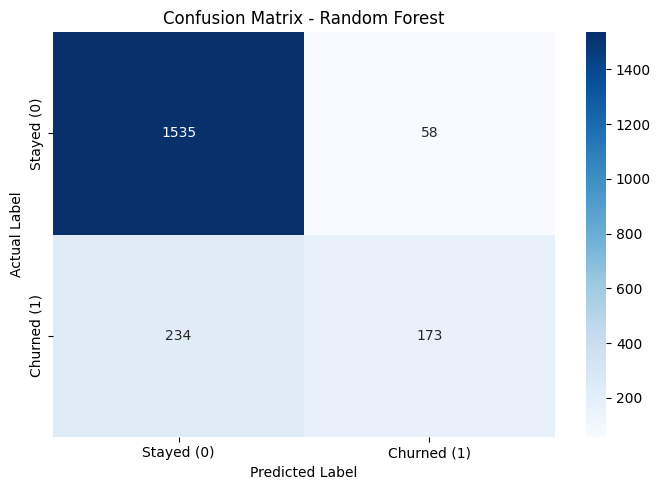


SAVED FILES
model_comparison_results.csv: True
final_test_results.csv: True
best_churn_model.joblib: True

MODELING AND EVALUATION COMPLETED SUCCESSFULLY.


In [5]:

# ============================================================
# BANK CUSTOMER CHURN PREDICTION
# PROJECT 4: MODELING AND EVALUATION
# ============================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 0. PROJECT TITLE
# ------------------------------------------------------------

print("=" * 65)
print("PROJECT 4: MODELING AND EVALUATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD FEATURED DATASET
# ------------------------------------------------------------

dataset_path = "Churn_Modelling_Featured.csv"

if not os.path.exists(dataset_path):
    try:
        from google.colab import files

        print("\nPlease upload Churn_Modelling_Featured.csv")
        uploaded = files.upload()

        if dataset_path not in uploaded and not os.path.exists(dataset_path):
            raise FileNotFoundError(
                "Churn_Modelling_Featured.csv was not uploaded."
            )

    except ImportError:
        raise FileNotFoundError(
            "Place Churn_Modelling_Featured.csv beside this notebook."
        )

df = pd.read_csv(dataset_path)

if "Exited" not in df.columns:
    raise ValueError("Target column 'Exited' was not found.")

df = df.dropna(subset=["Exited"]).copy()
df["Exited"] = df["Exited"].astype(int)

if not set(df["Exited"].unique()).issubset({0, 1}):
    raise ValueError("The target column must contain only 0 and 1.")

print("\nDataset shape:", df.shape)
print("Stayed (0):", (df["Exited"] == 0).sum())
print("Churned (1):", (df["Exited"] == 1).sum())

# ------------------------------------------------------------
# 2. SEPARATE FEATURES AND TARGET
# ------------------------------------------------------------

X = df.drop(columns=["Exited"])
y = df["Exited"]

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# ------------------------------------------------------------
# 4. PREPROCESSING
# Fit preprocessing separately within each CV fold.
# This helps prevent data leakage.
# ------------------------------------------------------------

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

# ------------------------------------------------------------
# 5. SELECT MACHINE LEARNING MODELS
# ------------------------------------------------------------

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=-1
    )
}

# ------------------------------------------------------------
# 6. CROSS-VALIDATION AND MODEL COMPARISON
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []

print("\nStarting 5-fold cross-validation...")

for model_name, classifier in classifiers.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    results.append({
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

    print(f"Completed: {model_name}")

# Create comparison table
cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by="CV F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("CROSS-VALIDATION MODEL COMPARISON")
print("=" * 65)

# Print as plain text to avoid interactive dataframe display issues
print(cv_results.round(4).to_string(index=False))

# Save comparison results
cv_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

# ------------------------------------------------------------
# 7. SELECT THE BEST MODEL USING MEAN CV F1
# ------------------------------------------------------------

best_model_name = cv_results.loc[0, "Model"]
best_classifier = classifiers[best_model_name]

print("\nSelected model:", best_model_name)
print("Selection criterion: Highest mean cross-validation F1-score")

# ------------------------------------------------------------
# 8. TRAIN THE SELECTED MODEL
# ------------------------------------------------------------

best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", best_classifier)
])

best_model.fit(X_train, y_train)

print("\nBest model trained successfully.")

# ------------------------------------------------------------
# 9. EVALUATE ON UNSEEN TEST DATA
# ------------------------------------------------------------

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Test Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

print("\n" + "=" * 65)
print("FINAL TEST RESULTS")
print("=" * 65)

print(test_results_df.round(4).to_string(index=False))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Stayed", "Churned"],
    zero_division=0
))

# ------------------------------------------------------------
# 10. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed (0)", "Churned (1)"],
    yticklabels=["Stayed (0)", "Churned (1)"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. SAVE THE SELECTED MODEL AND RESULTS
# ------------------------------------------------------------

joblib.dump(best_model, "best_churn_model.joblib")

# Save final test metrics
test_results_df.to_csv(
    "final_test_results.csv",
    index=False
)

print("\n" + "=" * 65)
print("SAVED FILES")
print("=" * 65)

files_to_check = [
    "model_comparison_results.csv",
    "final_test_results.csv",
    "best_churn_model.joblib"
]

for filename in files_to_check:
    print(f"{filename}: {os.path.exists(filename)}")

print("\nMODELING AND EVALUATION COMPLETED SUCCESSFULLY.")
